In [ ]:
import pandas as pd

# Load the dataset
file_path = '/content/Influenza__COVID-19__RSV__and_Other_Respiratory_Virus_Laboratory_Surveillance.csv'
df = pd.read_csv(file_path)

# Display column names to verify exact matches
print("Original Columns:")
print(df.columns.tolist())


Original Columns:
['mmwr_week', 'week', 'week_start', 'week_end', 'season', 'pathogen', 'lab_tot_tested', 'lab_tot_positive', 'lab_pct_positive', 'lab_tot_tested_cumulative', 'lab_tot_positive_cumulative', 'lab_pct_positive_cumulative', 'current_week_ending', 'row_id']


In [ ]:
import pandas as pd

# Ensure week_start is in datetime format
df['week_start'] = pd.to_datetime(df['week_start'], errors='coerce')

# Extract month
df['month'] = df['week_start'].dt.month

# Map months to season names
# 12, 1, 2 -> Winter; 3, 4, 5 -> Spring; 6, 7, 8 -> Summer; 9, 10, 11 -> Autumn
def get_season_name(month):
    if pd.isna(month):
        return None
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

df['season'] = df['month'].apply(get_season_name)

# Retain only the specified columns and drop any invalid rows
df_seasonal = df[['season', 'pathogen', 'month']].copy()
df_seasonal = df_seasonal.dropna()
df_seasonal['month'] = df_seasonal['month'].astype(int)

# Save the final dataset
df_seasonal.to_csv('seasonal_pathogen_records.csv', index=False)

print("Processing complete! Season years have been converted to season names based on month.")
display(df_seasonal.head(10))

Processing complete! Season years have been converted to season names based on month.


,season,pathogen,month
0,Autumn,Influenza,10
1,Autumn,Influenza,10
2,Autumn,Influenza,10
3,Autumn,Influenza,10
4,Winter,Adenovirus,1
5,Winter,Seasonal Coronaviruse,1
6,Winter,Seasonal Coronaviruse,12
7,Winter,Rhinovirus/Enteroviru,12
8,Winter,Seasonal Coronaviruse,12
9,Winter,Adenovirus,12


In [ ]:
import pandas as pd

# Load datasets
df_pathogen = pd.read_csv('seasonal_pathogen_records.csv')
df_satellite = pd.read_csv('/content/satellite_data.csv')

# Standardize the month column name
df_satellite_aligned = df_satellite.rename(columns={'Month': 'month'})

# Count unique values per month in both datasets to understand the duplication
pathogen_counts = df_pathogen['month'].value_counts().sort_index()
satellite_counts = df_satellite_aligned['month'].value_counts().sort_index()

print("--- Unique Months and Row Counts ---")
print("Month | Pathogen Rows | Satellite Rows | Expected Merge Rows (Pathogen x Satellite)")
total_expected = 0
for m in sorted(list(set(pathogen_counts.index).union(set(satellite_counts.index)))):
    p_cnt = pathogen_counts.get(m, 0)
    s_cnt = satellite_counts.get(m, 0)
    expected = p_cnt * s_cnt
    total_expected += expected
    print(f"{int(m):5d} | {p_cnt:13d} | {int(s_cnt):14d} | {expected:d}")

print(f"\nTotal Expected Rows after Merge: {total_expected:,}")

# Perform a safe, limited trial merge to verify behavior
try:
    # Only merge a tiny subset to show it works, as a full merge might crash Colab's RAM
    sample_merge = pd.merge(df_pathogen.head(10), df_satellite_aligned, on='month', how='inner')
    print(f"\nTrial Merge successful with sample subset. Merging just the first 10 rows of pathogen data resulted in {len(sample_merge)} rows.")
except Exception as e:
    print(f"Error during trial merge: {e}")

--- Unique Months and Row Counts ---
Month | Pathogen Rows | Satellite Rows | Expected Merge Rows (Pathogen x Satellite)
    1 |           288 |           8364 | 2408832
    2 |           260 |           7526 | 1956760
    3 |           296 |           9832 | 2910272
    4 |           271 |           8187 | 2218677
    5 |           271 |           8349 | 2262579
    6 |           247 |           8445 | 2085915
    7 |           249 |           5938 | 1478562
    8 |           254 |           5572 | 1415288
    9 |           247 |           5239 | 1294033
   10 |           288 |           6148 | 1770624
   11 |           278 |           7721 | 2146438
   12 |           288 |           8114 | 2336832

Total Expected Rows after Merge: 24,284,812

Trial Merge successful with sample subset. Merging just the first 10 rows of pathogen data resulted in 73776 rows.


In [ ]:
import pandas as pd

# 1. Load the pathogen and satellite datasets
df_pathogen = pd.read_csv('seasonal_pathogen_records.csv')
df_satellite = pd.read_csv('/content/satellite_data.csv')

# 2. Align the month columns
df_satellite_aligned = df_satellite.rename(columns={'Month': 'month'})

# 3. Aggregate satellite metrics by month to avoid Cartesian product explosion
# We will calculate the average (mean) value for all numerical columns grouped by month
satellite_monthly_avg = df_satellite_aligned.groupby('month', as_index=False).mean()

# 4. Merge the datasets safely
df_merged = pd.merge(df_pathogen, satellite_monthly_avg, on='month', how='left')

# 5. Display the information and preview
print(f"Pathogen dataset shape: {df_pathogen.shape}")
print(f"Aggregated satellite dataset shape: {satellite_monthly_avg.shape}")
print(f"Successfully merged dataset shape: {df_merged.shape}\n")

display(df_merged.head(10))

Pathogen dataset shape: (3237, 3)
Aggregated satellite dataset shape: (12, 13)
Successfully merged dataset shape: (3237, 15)



,season,pathogen,month,PM2.5,PM10,NO2,CO,SO2,O3,Temperature_C,Relative_Humidity_pct,Wind_Speed_kmh,Hour,DayOfWeek,DayOfYear
0,Autumn,Influenza,10,71.541181,88.385454,30.216636,1.053069,19.624388,37.449909,26.479652,79.297332,7.261679,11.497235,2.876708,290.151919
1,Autumn,Influenza,10,71.541181,88.385454,30.216636,1.053069,19.624388,37.449909,26.479652,79.297332,7.261679,11.497235,2.876708,290.151919
2,Autumn,Influenza,10,71.541181,88.385454,30.216636,1.053069,19.624388,37.449909,26.479652,79.297332,7.261679,11.497235,2.876708,290.151919
3,Autumn,Influenza,10,71.541181,88.385454,30.216636,1.053069,19.624388,37.449909,26.479652,79.297332,7.261679,11.497235,2.876708,290.151919
4,Winter,Adenovirus,1,132.659358,129.265505,41.515086,1.374827,17.914974,44.198250,20.546891,74.096126,7.804878,11.473219,2.915232,15.903515
5,Winter,Seasonal Coronaviruse,1,132.659358,129.265505,41.515086,1.374827,17.914974,44.198250,20.546891,74.096126,7.804878,11.473219,2.915232,15.903515
6,Winter,Seasonal Coronaviruse,12,126.700580,111.123413,37.926753,1.407494,15.889433,46.354756,21.727471,72.462041,8.536653,11.434434,2.995933,349.769904
7,Winter,Rhinovirus/Enteroviru,12,126.700580,111.123413,37.926753,1.407494,15.889433,46.354756,21.727471,72.462041,8.536653,11.434434,2.995933,349.769904
8,Winter,Seasonal Coronaviruse,12,126.700580,111.123413,37.926753,1.407494,15.889433,46.354756,21.727471,72.462041,8.536653,11.434434,2.995933,349.769904
9,Winter,Adenovirus,12,126.700580,111.123413,37.926753,1.407494,15.889433,46.354756,21.727471,72.462041,8.536653,11.434434,2.995933,349.769904


In [ ]:
import pandas as pd

# 1. Check for missing values in the merged dataset
missing_report = df_merged.isnull().sum()
print("--- Missing Values Report ---")
print(missing_report[missing_report > 0] if missing_report.sum() > 0 else "No missing values found!")

# 2. Handle missing values if any exist (safety step)
if df_merged.isnull().sum().sum() > 0:
    # Fill numerical columns with median and categorical with mode
    for col in df_merged.columns:
        if df_merged[col].dtype in ['float64', 'int64']:
            df_merged[col] = df_merged[col].fillna(df_merged[col].median())
        else:
            df_merged[col] = df_merged[col].fillna(df_merged[col].mode()[0])
    print("\nMissing values handled successfully.")
else:
    print("\nNo preprocessing for missing values was needed as the dataset is already fully complete.")

--- Missing Values Report ---
No missing values found!

No preprocessing for missing values was needed as the dataset is already fully complete.


### 1. Histogram: PM2.5 Concentration Distribution

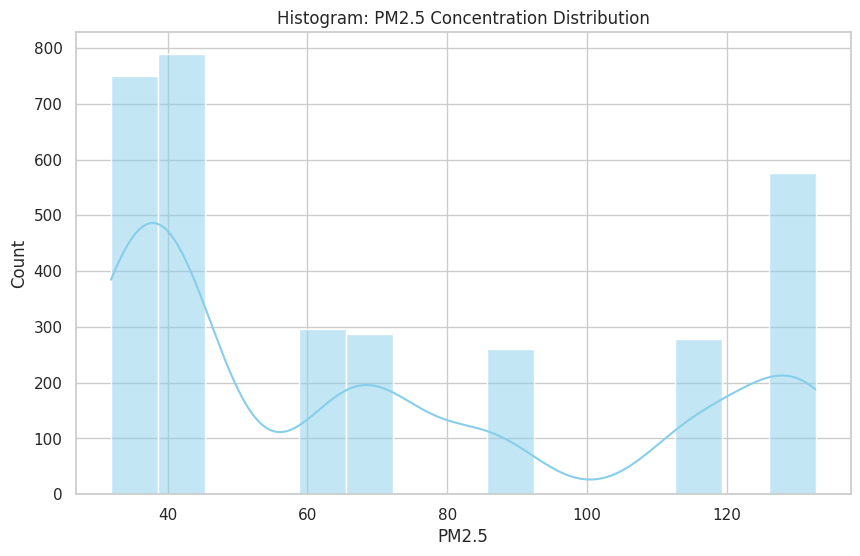

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.histplot(df_merged['PM2.5'], bins=15, kde=True, color='skyblue')
plt.title('Histogram: PM2.5 Concentration Distribution')
plt.xlabel('PM2.5')
plt.ylabel('Count')
plt.show()

### 2. Scatter Plot: Temperature vs PM2.5

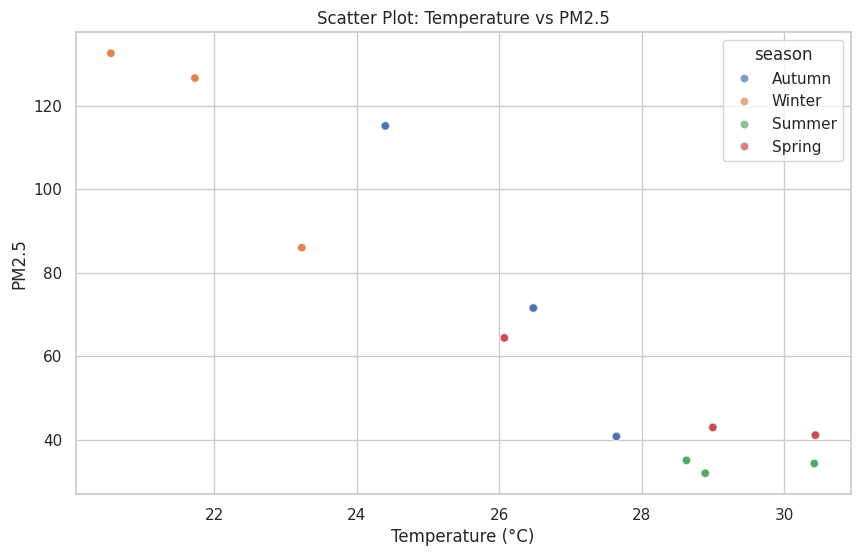

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_merged, x='Temperature_C', y='PM2.5', hue='season', alpha=0.7)
plt.title('Scatter Plot: Temperature vs PM2.5')
plt.xlabel('Temperature (°C)')
plt.ylabel('PM2.5')
plt.show()

### 3. Box Plot: PM10 Concentration by Season

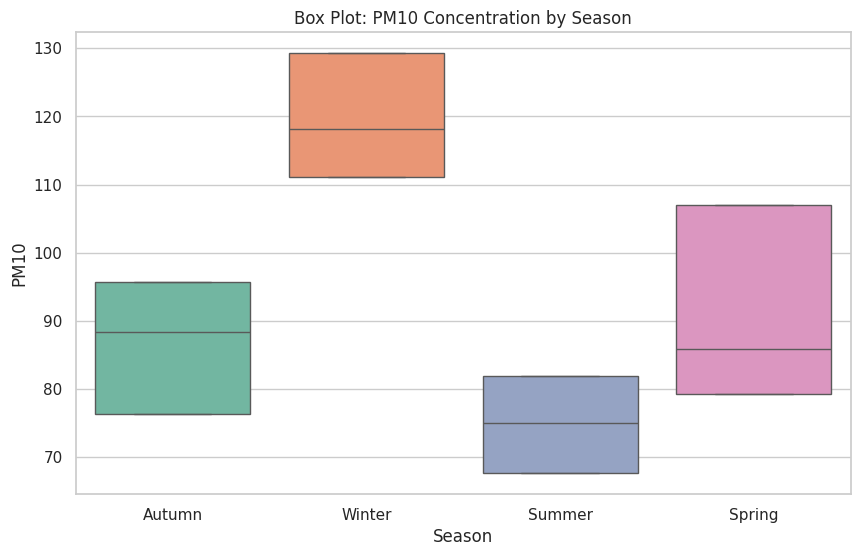

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_merged, x='season', y='PM10', hue='season', palette='Set2', legend=False)
plt.title('Box Plot: PM10 Concentration by Season')
plt.xlabel('Season')
plt.ylabel('PM10')
plt.show()

### 4. Clustered Bar Chart: Pathogen Counts by Season

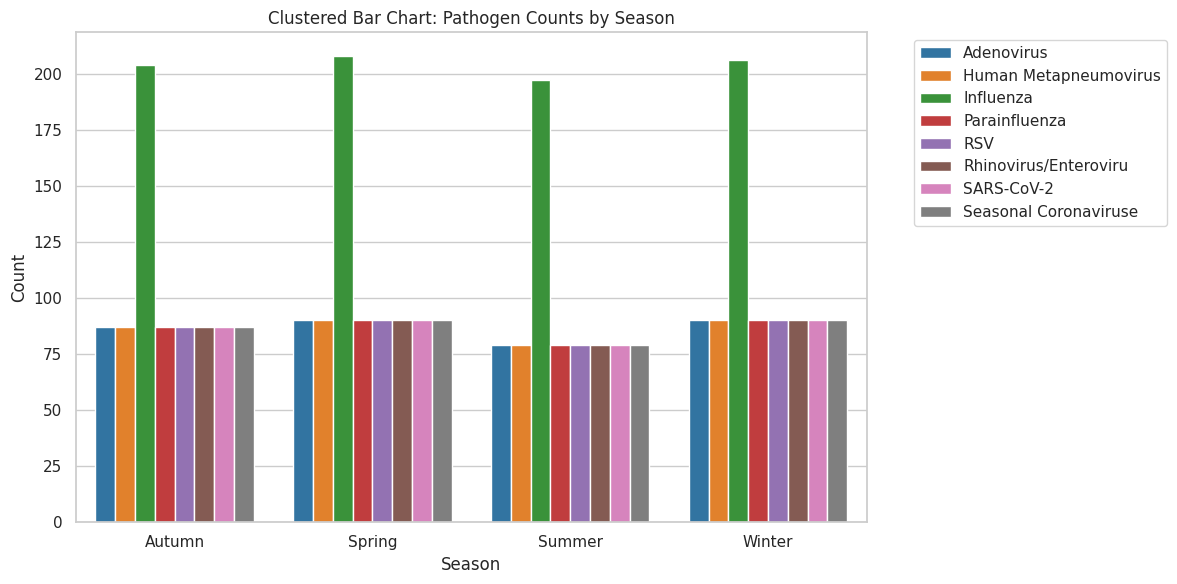

In [ ]:
plt.figure(figsize=(12, 6))
pathogen_season_counts = df_merged.groupby(['season', 'pathogen']).size().reset_index(name='count')
sns.barplot(data=pathogen_season_counts, x='season', y='count', hue='pathogen', palette='tab10')
plt.title('Clustered Bar Chart: Pathogen Counts by Season')
plt.xlabel('Season')
plt.ylabel('Count')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 5. Line and Stacked Column Chart: Monthly PM2.5 & PM10 Averages

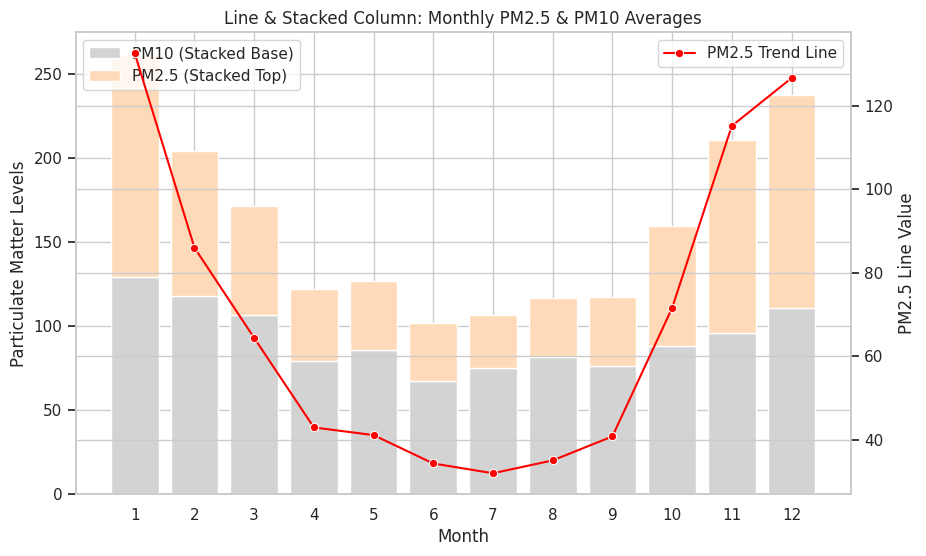

In [ ]:
fig, ax_bar = plt.subplots(figsize=(10, 6))
monthly_avgs = df_merged.groupby('month')[['PM2.5', 'PM10']].mean().reset_index()

ax_bar.bar(monthly_avgs['month'], monthly_avgs['PM10'], label='PM10 (Stacked Base)', color='lightgray')
ax_bar.bar(monthly_avgs['month'], monthly_avgs['PM2.5'], bottom=monthly_avgs['PM10'], label='PM2.5 (Stacked Top)', color='peachpuff')
ax_bar.set_ylabel('Particulate Matter Levels')
ax_bar.set_xlabel('Month')

ax_line = ax_bar.twinx()
sns.lineplot(data=monthly_avgs, x='month', y='PM2.5', color='red', marker='o', ax=ax_line, label='PM2.5 Trend Line')
ax_line.set_ylabel('PM2.5 Line Value')

plt.title('Line & Stacked Column: Monthly PM2.5 & PM10 Averages')
ax_bar.set_xticks(range(1, 13))
ax_bar.legend(loc='upper left')
ax_line.legend(loc='upper right')
plt.show()

### 6. Donut Chart: Season Share of Records

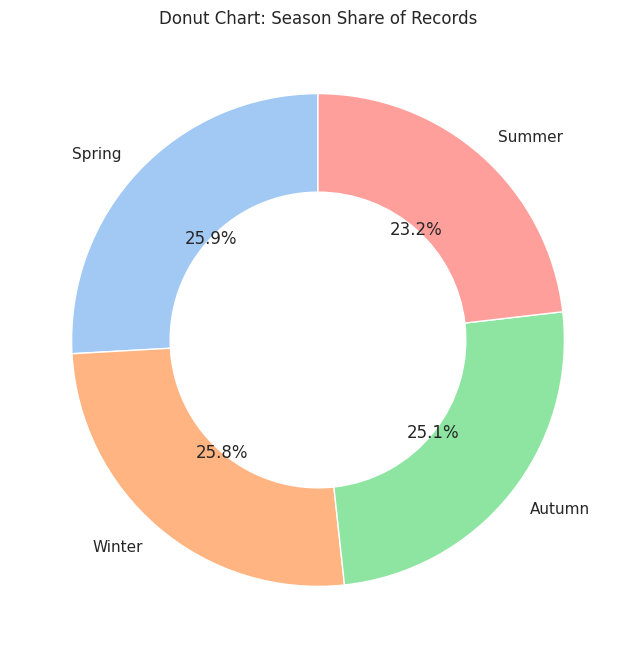

In [ ]:
plt.figure(figsize=(8, 8))
season_shares = df_merged['season'].value_counts()
plt.pie(season_shares, labels=season_shares.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'),
        wedgeprops=dict(width=0.4, edgecolor='w'))
plt.title('Donut Chart: Season Share of Records')
plt.show()

### 7. Pie Chart: Pathogen Share of Records

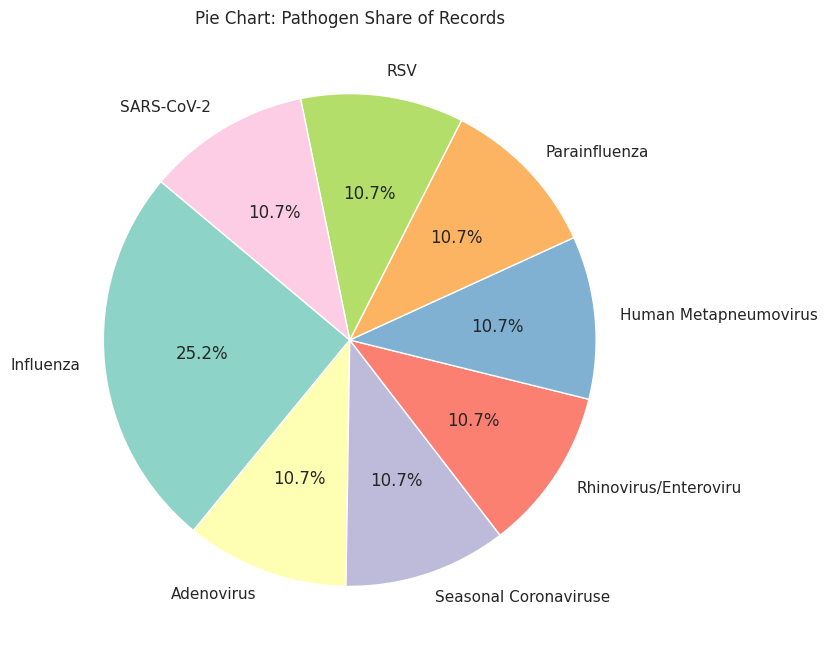

In [ ]:
plt.figure(figsize=(8, 8))
pathogen_shares = df_merged['pathogen'].value_counts()
plt.pie(pathogen_shares, labels=pathogen_shares.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('Set3'))
plt.title('Pie Chart: Pathogen Share of Records')
plt.show()

### 8. Line Chart: Monthly Mean Temperature and Humidity

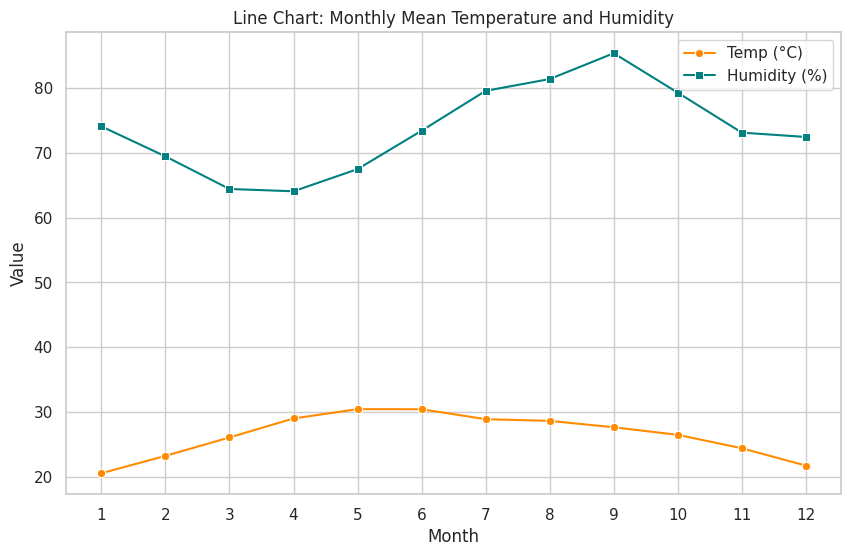

In [ ]:
plt.figure(figsize=(10, 6))
monthly_weather = df_merged.groupby('month')[['Temperature_C', 'Relative_Humidity_pct']].mean().reset_index()
sns.lineplot(data=monthly_weather, x='month', y='Temperature_C', marker='o', label='Temp (°C)', color='darkorange')
sns.lineplot(data=monthly_weather, x='month', y='Relative_Humidity_pct', marker='s', label='Humidity (%)', color='teal')
plt.title('Line Chart: Monthly Mean Temperature and Humidity')
plt.xticks(range(1, 13))
plt.xlabel('Month')
plt.ylabel('Value')
plt.legend()
plt.show()

In [ ]:
# Verify missing values in the final merged dataset
null_counts = df_merged.isnull().sum()
total_missing = null_counts.sum()

print("=== Missing Value Verification Report ===")
if total_missing == 0:
    print("Excellent! There are absolutely NO missing values in the merged dataset.")
else:
    print(f"Found a total of {total_missing} missing values:")
    display(null_counts[null_counts > 0])

# Also show information summary to confirm non-null counts match the total row count
print("\n--- Dataset Column Information ---")
df_merged.info()

=== Missing Value Verification Report ===
Excellent! There are absolutely NO missing values in the merged dataset.

--- Dataset Column Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3237 entries, 0 to 3236
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   season                 3237 non-null   object 
 1   pathogen               3237 non-null   object 
 2   month                  3237 non-null   int64  
 3   PM2.5                  3237 non-null   float64
 4   PM10                   3237 non-null   float64
 5   NO2                    3237 non-null   float64
 6   CO                     3237 non-null   float64
 7   SO2                    3237 non-null   float64
 8   O3                     3237 non-null   float64
 9   Temperature_C          3237 non-null   float64
 10  Relative_Humidity_pct  3237 non-null   float64
 11  Wind_Speed_kmh         3237 non-null   float64
 12  Hour     

In [ ]:
from google.colab import files

# Save the final merged dataset to a CSV file
output_filename = 'final_merged_respiratory_satellite_data.csv'
df_merged.to_csv(output_filename, index=False)

# Trigger the browser download
files.download(output_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>